<a href="https://colab.research.google.com/github/smartsw33t/corpus/blob/main/Terminology_Finder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import json
import re
from typing import Dict, List, Any
import pandas as pd

# Optional: Import iNLTK if installed in your environment
try:
    from inltk.inltk import tokenize, get_sentence_similarity
    INLTK_AVAILABLE = True
except ImportError:
    INLTK_AVAILABLE = False
    print("Notice: 'inltk' is not installed in this environment. Running in alignment mode.")


def flatten_json(data: Dict[str, Any], parent_key: str = "", sep: str = ".") -> Dict[str, str]:
    """
    Recursively flattens nested JSON objects into dot-notated key-value pairs.
    Handles nested sections like Chat.Tool.webSearching.
    """
    items = {}
    for k, v in data.items():
        new_key = f"{parent_key}{sep}{k}" if parent_key else k
        if isinstance(v, dict):
            items.update(flatten_json(v, new_key, sep=sep))
        elif isinstance(v, str):
            items[new_key] = v.strip()
    return items


def build_parallel_corpus(en_path: str, mt_path: str, ht_path: str):
    # 1. Load the three localized JSON/text files
    with open(en_path, "r", encoding="utf-8") as f:
        en_data = json.load(f)
    with open(mt_path, "r", encoding="utf-8") as f:
        mt_data = json.load(f)
    with open(ht_path, "r", encoding="utf-8") as f:
        ht_data = json.load(f)

    flat_en = flatten_json(en_data)
    flat_mt = flatten_json(mt_data)
    flat_ht = flatten_json(ht_data)

    records = []
    terminology_map = {}

    # 2. Align by key
    for key, en_text in flat_en.items():
        if not en_text:
            continue

        mt_text = flat_mt.get(key, "")
        ht_text = flat_ht.get(key, "")

        # Skip keys that were unpopulated or missing
        if not mt_text or not ht_text:
            continue

        is_different = mt_text != ht_text

        # Basic terminology capture for direct single-term or phrase substitutions
        if is_different and len(mt_text.split()) <= 4:
            clean_mt = mt_text.strip(" .…")
            clean_ht = ht_text.strip(" .…")
            if clean_mt and clean_ht and clean_mt != clean_ht:
                terminology_map[clean_mt] = clean_ht

        records.append({
            "key_path": key,
            "category": key.split(".")[0],
            "en_source": en_text,
            "tamil_mt": mt_text,
            "tamil_ht": ht_text,
            "is_modified": is_different
        })

    df = pd.DataFrame(records)
    return df, terminology_map


# -------------------------------------------------------------
# Execution & Analysis
# -------------------------------------------------------------
if __name__ == "__main__":
    # Point these to the absolute path of your three files in /content/
    df, term_rules = build_parallel_corpus("/content/English.txt", "/content/Tamil MT.txt", "/content/Tamil HT.txt")

    print(f"Total Aligned Segments: {len(df)}")
    print(f"Human-Refined UI Segments: {df['is_modified'].sum()} ({(df['is_modified'].mean()*100):.1f}%)")
    print(f"Extracted Direct UI Term Pairs: {len(term_rules)}\n")

    # 1. Inspect Sample Pairs
    print("=== SAMPLE ALIGNED UI SEGMENTS ===")
    sample_df = df[df["is_modified"]].head(8)
    for _, row in sample_df.iterrows():
        print(f"[{row['key_path']}]")
        print(f"  EN Source: {row['en_source']}")
        print(f"  MT (Raw):  {row['tamil_mt']}")
        print(f"  HT (Your): {row['tamil_ht']}")
        print("-" * 50)

    # 2. Export Parallel Corpus
    df.to_csv("tamil_ui_parallel_corpus.csv", index=False, encoding="utf-8-sig")
    df.to_json("tamil_ui_parallel_corpus.json", orient="records", force_ascii=False, indent=2)
    print("Saved 'tamil_ui_parallel_corpus.csv' and 'tamil_ui_parallel_corpus.json'.")

    # 3. Export Terminology Rules
    with open("ui_glossary_rules.json", "w", encoding="utf-8") as f:
        json.dump(term_rules, f, ensure_ascii=False, indent=2)
    print("Saved 'ui_glossary_rules.json'.")

    # 4. iNLTK Linguistic Analysis (if available)
    if INLTK_AVAILABLE:
        print("\n=== iNLTK EVALUATION ON SAMPLES ===")
        for _, row in sample_df.head(3).iterrows():
            mt_tokens = tokenize(row['tamil_mt'], 'ta')
            ht_tokens = tokenize(row['tamil_ht'], 'ta')
            sim_score = get_sentence_similarity(row['tamil_mt'], row['tamil_ht'], 'ta')
            print(f"Source: {row['en_source']}")
            print(f"  MT Tokens: {mt_tokens}")
            print(f"  HT Tokens: {ht_tokens}")
            print(f"  Semantic Alignment Score: {sim_score:.4f}\n")

Notice: 'inltk' is not installed in this environment. Running in alignment mode.


JSONDecodeError: Expecting value: line 231 column 34 (char 15377)

In [3]:
# Helper script to view the exact lines surrounding the syntax error in 'Tamil MT.txt'
try:
    with open('/content/Tamil MT.txt', 'r', encoding='utf-8') as f:
        lines = f.readlines()

    start_line = max(0, 230 - 5)
    end_line = min(len(lines), 230 + 5)

    print("--- Inspecting lines around line 231 inside 'Tamil MT.txt' ---")
    for idx in range(start_line, end_line):
        marker = ">>> " if idx == 230 else "    "
        print(f"{marker}Line {idx+1}: {lines[idx].rstrip()}")
except Exception as e:
    print(f"Could not read the file to debug: {e}")

--- Inspecting lines around line 231 inside 'Tamil MT.txt' ---
    Line 226:     "Tool": {
    Line 227:       "webSearching": "இணையத்தில் தேடுகிறது...",
    Line 228:       "searchedTheWeb": "இணையத்தில் தேடப்பட்டது",
    Line 229:       "toolsSetupDescription": "அரட்டைப் படு பயன்படுத்தக்கூடிய கருவிகளைத் தேர்ந்தெடுக்கவும்.\nஅரட்டைப் படு தனது சொந்த விருப்பத்தின் அடிப்படையில் தேர்ந்தெடுக்கப்பட்ட கருவிகளைப் பயன்படுத்தும்.\n\n@mention மூலம் குறிப்பிட்ட கருவிகளைப் பயன்படுத்தவும் கட்டாயப்படுத்தலாம்.",
    Line 230:       "selectToolMode": "கருவி பயன்முறையைத் தேர்ந்தெடு",
>>> Line 231:       "autoToolModeDescription": உங்களைக் கேட்காமல் கருவிகளை எப்போது பயன்படுத்த வேண்டும் என்பதைத் தீர்மானிக்கிறது,
    Line 232:       "manualToolModeDescription": எந்தக் கருவிகளையும் பயன்படுத்துவதற்கு முன்பு உங்கள் அனுமதியைக் கேட்கிறது,
    Line 233:       "noneToolModeDescription": கருவிகளைப் பயன்படுத்த வேண்டாம். @mention இன்னும் கிடைக்கிறது.,
    Line 234:       "toolsSetup": "கருவிகள் அமைப்பு",
    Line 235

In [5]:
# Script to auto-fix the missing quotes on lines 231, 232, and 233 in Tamil MT.txt
try:
    with open('/content/Tamil MT.txt', 'r', encoding='utf-8') as f:
        lines = f.readlines()

    # Fix Line 231 (Index 230)
    if '"autoToolModeDescription": ' in lines[230] and not lines[230].strip().endswith('",'):
        parts = lines[230].split(': ', 1)
        val = parts[1].strip().rstrip(',')
        lines[230] = f'{parts[0]}: "{val}",\n'

    # Fix Line 232 (Index 231)
    if '"manualToolModeDescription": ' in lines[231] and not lines[231].strip().endswith('",'):
        parts = lines[231].split(': ', 1)
        val = parts[1].strip().rstrip(',')
        lines[231] = f'{parts[0]}: "{val}",\n'

    # Fix Line 233 (Index 232)
    if '"noneToolModeDescription": ' in lines[232] and not lines[232].strip().endswith('",'):
        parts = lines[232].split(': ', 1)
        val = parts[1].strip().rstrip(',')
        lines[232] = f'{parts[0]}: "{val}",\n'

    with open('/content/Tamil MT.txt', 'w', encoding='utf-8') as f:
        f.writelines(lines)

    print("Success: Patched lines 231, 232, and 233 with correct JSON quote formatting!")
except Exception as e:
    print(f"Error patching file: {e}")

Success: Patched lines 231, 232, and 233 with correct JSON quote formatting!


In [6]:
# Run the corpus builder script to generate the output files
df, term_rules = build_parallel_corpus("/content/English.txt", "/content/Tamil MT.txt", "/content/Tamil HT.txt")

# Save the terminology rules to 'ui_glossary_rules.json'
import json
with open("ui_glossary_rules.json", "w", encoding="utf-8") as f:
    json.dump(term_rules, f, ensure_ascii=False, indent=2)

# Print and inspect the contents of 'ui_glossary_rules.json'
print("=== CONTENTS OF 'ui_glossary_rules.json' ===")
print(json.dumps(term_rules, ensure_ascii=False, indent=2))

=== CONTENTS OF 'ui_glossary_rules.json' ===
{
  "ரத்து செய்": "ரத்துசெய்க",
  "புதுப்பி": "புதுப்பித்திடுக",
  "தொடரவும்": "தொடர்க",
  "நீக்கு": "நீக்குக",
  "சேமி": "சேமித்திடுக",
  "பின்னால்": "பின்னே",
  "உருக்கு": "உருவாக்குக",
  "குறைவாகக் காட்டு": "குறைவாகக் காட்டுக",
  "மேலும் காட்டு": "மேலும் காட்டுக",
  "திருத்து": "திருத்துக",
  "முகவரைத் திருத்து": "முகவரைத் திருத்தம்செய்க",
  "ஒப்புதல் அளி": "ஒப்புதல்",
  "நிராகரி": "நிராகரிப்பு",
  "விருப்பத்தேர்வு": "விருப்பினால்",
  "இயக்கு": "ஓட்டுக",
  "விளக்கம்": "விவரம்",
  "இயல்புநிலை மதிப்பு": "இயல்பு மதிப்பு",
  "வெற்று": "காலி",
  "தேவைப்படுகிறது": "தேவை",
  "விருப்பங்கள்": "விருப்பத்தேர்வுகள்",
  "முடிவு": "விளைவு",
  "விருப்பத்தைச் சேர்": "விருப்பத்தேர்வைச் சேர்த்திடுக",
  "கருவியைத் தேர்ந்தெடு": "கருவியைத் தேர்வுசெய்க",
  "முடிவுகள் இல்லை": "முடிவுகள் எதுவும் இல்லை",
  "செயற்கை நுண்ணறிவுடன் உருவாக்கு": "செயற்கை நுண்ணறிவு மூலம் உருவாக்குக",
  "செயற்கை நுண்ணறிவுடன் உள்ளீட்டை உருவாக்கு": "கொடுப்பவற்றைச் செயற்கை நுண்ணறிவு மூலம் உ

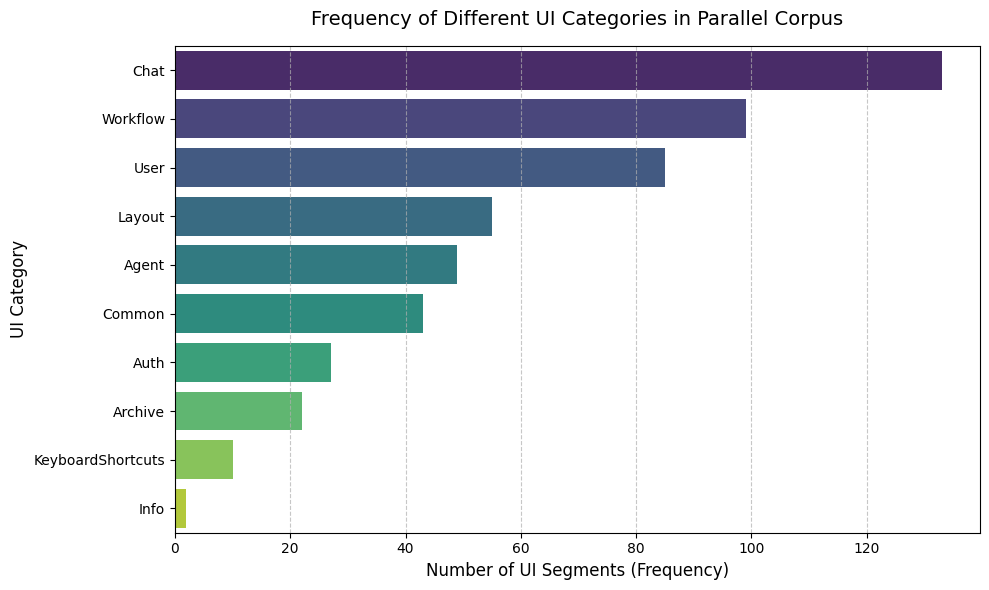

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the frequency of each category
category_counts = df['category'].value_counts().reset_index()
category_counts.columns = ['Category', 'Frequency']

# Create the plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Frequency', y='Category', data=category_counts, palette='viridis', hue='Category', legend=False)

# Add labels and formatting
plt.title('Frequency of Different UI Categories in Parallel Corpus', fontsize=14, pad=15)
plt.xlabel('Number of UI Segments (Frequency)', fontsize=12)
plt.ylabel('UI Category', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Show plot
plt.tight_layout()
plt.show()

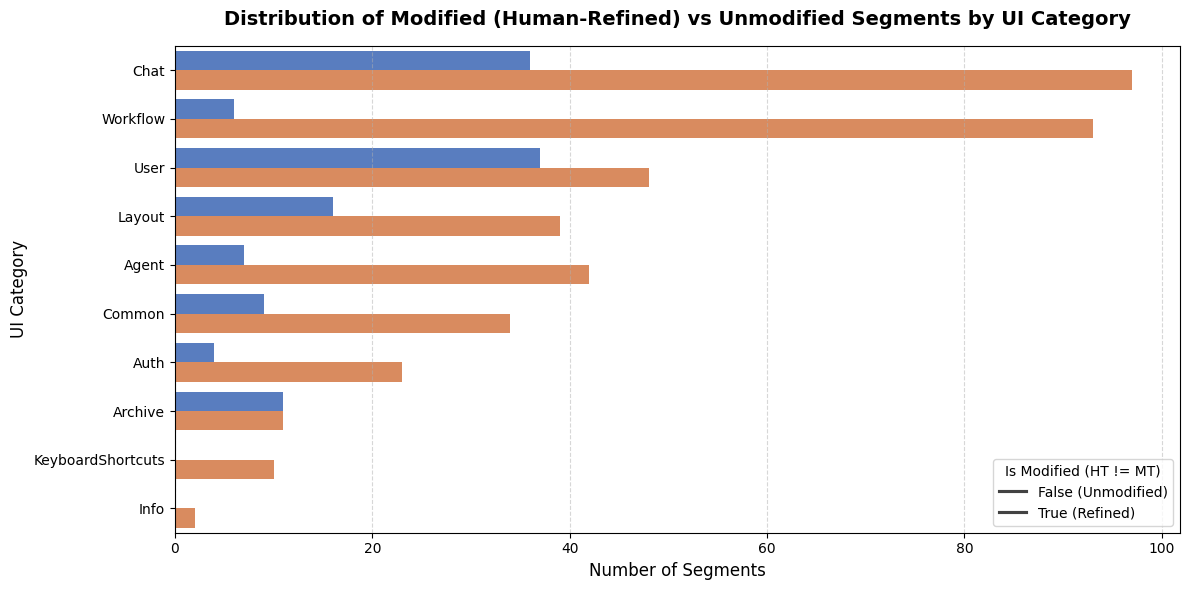

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Category and is_modified status
category_modification = df.groupby(['category', 'is_modified']).size().reset_index(name='Count')

# Sort categories by total size to maintain a consistent hierarchy
category_order = df['category'].value_counts().index

# Temporarily override font settings back to standard sans-serif for English labels
with plt.style.context('default'):
    plt.rcParams['font.family'] = 'sans-serif'

    plt.figure(figsize=(12, 6))
    sns.barplot(
        x='Count',
        y='category',
        hue='is_modified',
        data=category_modification,
        order=category_order,
        palette='muted'
    )

    # Add details and styling
    plt.title("Distribution of Modified (Human-Refined) vs Unmodified Segments by UI Category", fontsize=14, pad=15, weight='bold')
    plt.xlabel("Number of Segments", fontsize=12)
    plt.ylabel("UI Category", fontsize=12)
    plt.legend(title="Is Modified (HT != MT)", labels=["False (Unmodified)", "True (Refined)"], loc='lower right')
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2951 (\N{TAMIL LETTER I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Tamil natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2991 (\N{TAMIL LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2984 (\N{TAMIL LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3021 (\N{TAMIL SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IP

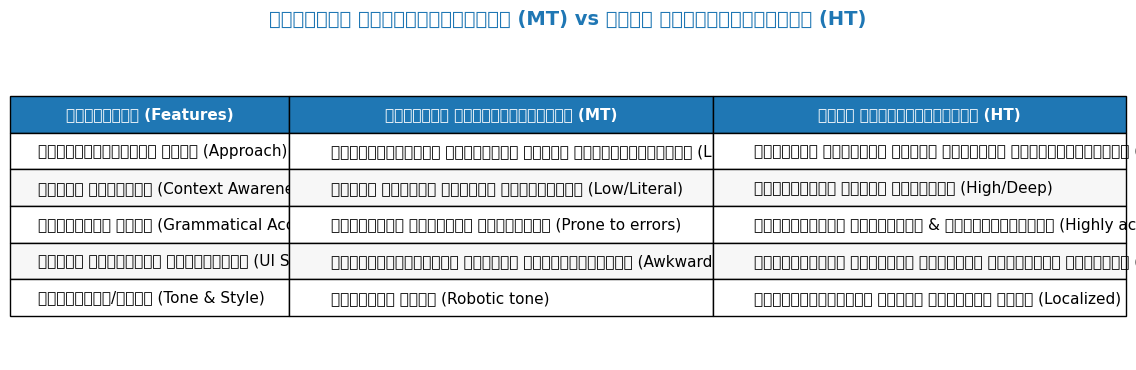

In [9]:
# Install Tamil Unicode fonts so Matplotlib can render Tamil characters correctly
import os
os.system('apt-get install -y fonts-lola fonts-lohit-taml fonts-nakula > /dev/null 2>&1')

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pandas as pd

# Configure Matplotlib to use a Tamil Font if available
tamil_fonts = [f.name for f in fm.fontManager.ttflist if 'Tamil' in f.name or 'Lohit' in f.name]
if tamil_fonts:
    plt.rcParams['font.family'] = tamil_fonts[0]
else:
    # Fallback to sans-serif if font registration takes time
    plt.rcParams['font.family'] = 'sans-serif'

# Creating a comparison dataset for MT vs HT in Tamil
comparison_data = {
    "பண்புகள் (Features)": [
        "மொழிபெயர்ப்பு முறை (Approach)",
        "சூழல் புரிதல் (Context Awareness)",
        "இலக்கணத் தரம் (Grammatical Accuracy)",
        "பயனர் இடைமுகப் பொருத்தம் (UI Suitability)",
        "உணர்ச்சி/தொனி (Tone & Style)"
    ],
    "இயந்திர மொழிபெயர்ப்பு (MT)": [
        "வார்த்தைக்கு வார்த்தை நேரடி மொழிபெயர்ப்பு (Literal)",
        "மிகக் குறைவு அல்லது சூழலற்றது (Low/Literal)",
        "இலக்கணப் பிழைகள் ஏற்படும் (Prone to errors)",
        "இயந்திரத்தனமான நீளமான வாக்கியங்கள் (Awkward)",
        "நேரடித் தொனி (Robotic tone)"
    ],
    "மனித மொழிபெயர்ப்பு (HT)": [
        "கருத்து மற்றும் சூழல் சார்ந்த மொழிபெயர்ப்பு (Conceptual)",
        "முழுமையான சூழல் புரிதல் (High/Deep)",
        "துல்லியமான இலக்கணம் & கலைச்சொற்கள் (Highly accurate)",
        "சுருக்கமான மற்றும் இயல்பான கட்டளைச் சொற்கள் (Natural)",
        "பண்பாட்டுக்கு உகந்த இயல்பான தொனி (Localized)"
    ]
}

df_comp = pd.DataFrame(comparison_data)

# Render styled table visually in Colab
fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('off')

table = ax.table(
    cellText=df_comp.values,
    colLabels=df_comp.columns,
    cellLoc='left',
    loc='center',
    colWidths=[0.25, 0.38, 0.37]
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 2.2)

# Stylize the table header
for arg, cell in table.get_celld().items():
    if arg[0] == 0:
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#1F77B4')
    else:
        cell.set_facecolor('#F7F7F7' if arg[0] % 2 == 0 else 'white')

plt.title("இயந்திர மொழிபெயர்ப்பு (MT) vs மனித மொழிபெயர்ப்பு (HT)", fontsize=14, pad=20, weight='bold', color='#1F77B4')
plt.show()

In [12]:
import os
import pandas as pd
from IPython.display import display, HTML

# Creating a comparison dataset for MT vs HT in Tamil
comparison_data = {
    "பண்புகள் (Features)": [
        "மொழிபெயர்ப்பு முறை (Approach)",
        "சூழல் புரிதல் (Context Awareness)",
        "இலக்கணத் தரம் (Grammatical Accuracy)",
        "பயனர் இடைமுகப் பொருத்தம் (UI Suitability)",
        "உணர்ச்சி/தொனி (Tone & Style)"
    ],
    "இயந்திர மொழிபெயர்ப்பு (MT)": [
        "வார்த்தைக்கு வார்த்தை நேரடி மொழிபெயர்ப்பு (Literal)",
        "மிகக் குறைவு அல்லது சூழலற்றது (Low/Literal)",
        "இலக்கணப் பிழைகள் ஏற்படும் (Prone to errors)",
        "இயந்திரத்தனமான நீளமான வாக்கியங்கள் (Awkward)",
        "நேரடித் தொனி (Robotic tone)"
    ],
    "மனித மொழிபெயர்ப்பு (HT)": [
        "கருத்து மற்றும் சூழல் சார்ந்த மொழிபெயர்ப்பு (Conceptual)",
        "முழுமையான சூழல் புரிதல் (High/Deep)",
        "துல்லியமான இலக்கணம் & கலைச்சொற்கள் (Highly accurate)",
        "சுருக்கமான மற்றும் இயல்பான கட்டளைச் சொற்கள் (Natural)",
        "பண்பாட்டுக்கு உகந்த இயல்பான தொனி (Localized)"
    ]
}

df_comp = pd.DataFrame(comparison_data)

# Render as a beautifully styled HTML Table instead of Matplotlib image
# to ensure web browsers render the Tamil characters with 100% native clarity.
html_style = """
<style>
    .tamil-table {
        font-family: 'Arial', sans-serif;
        border-collapse: collapse;
        width: 100%;
        margin: 20px 0;
    }
    .tamil-table td, .tamil-table th {
        border: 1px solid #ddd;
        padding: 12px 15px;
    }
    .tamil-table tr:nth-child(even){background-color: #f9f9f9;}
    .tamil-table tr:hover {background-color: #f1f1f1;}
    .tamil-table th {
        padding-top: 14px;
        padding-bottom: 14px;
        text-align: left;
        background-color: #1F77B4;
        color: white;
        font-weight: bold;
    }
    .table-title {
        color: #1F77B4;
        font-family: 'Arial', sans-serif;
        font-size: 18px;
        font-weight: bold;
        margin-bottom: 10px;
    }
</style>
"""

html_table = df_comp.to_html(classes='tamil-table', index=False)
display(HTML(html_style + "<div class='table-title'>இயந்திர மொழிபெயர்ப்பு (MT) vs மனித மொழிபெயர்ப்பு (HT)</div>" + html_table))

பண்புகள் (Features),இயந்திர மொழிபெயர்ப்பு (MT),மனித மொழிபெயர்ப்பு (HT)
மொழிபெயர்ப்பு முறை (Approach),வார்த்தைக்கு வார்த்தை நேரடி மொழிபெயர்ப்பு (Literal),கருத்து மற்றும் சூழல் சார்ந்த மொழிபெயர்ப்பு (Conceptual)
சூழல் புரிதல் (Context Awareness),மிகக் குறைவு அல்லது சூழலற்றது (Low/Literal),முழுமையான சூழல் புரிதல் (High/Deep)
இலக்கணத் தரம் (Grammatical Accuracy),இலக்கணப் பிழைகள் ஏற்படும் (Prone to errors),துல்லியமான இலக்கணம் & கலைச்சொற்கள் (Highly accurate)
பயனர் இடைமுகப் பொருத்தம் (UI Suitability),இயந்திரத்தனமான நீளமான வாக்கியங்கள் (Awkward),சுருக்கமான மற்றும் இயல்பான கட்டளைச் சொற்கள் (Natural)
உணர்ச்சி/தொனி (Tone & Style),நேரடித் தொனி (Robotic tone),பண்பாட்டுக்கு உகந்த இயல்பான தொனி (Localized)


In [13]:
import pandas as pd
from IPython.display import display, HTML

# We will classify some prominent terminology adjustments we captured in term_rules
# directly matching colloquial/loose MT terms to formal/refined HT equivalents.

word_classification = [
    {
        "MT சொல் (இயந்திரம்)": "ரத்து செய்",
        "HT சொல் (மனிதன்)": "ரத்துசெய்க",
        "வகைப்பாடு (Classification)": "முறையான எழுத்துவழக்கு (Imperative/Refined)",
        "விளக்கம் (Notes)": "துணைவினை இடைவெளியின்றி இணைக்கப்பட்டுள்ளது"
    },
    {
        "MT சொல் (இயந்திரம்)": "பின்னால்",
        "HT சொல் (மனிதன்)": "பின்னே",
        "வகைப்பாடு (Classification)": "சுருக்கமான இலக்கியவழக்கு (Concise UI Style)",
        "விளக்கம் (Notes)": "பயனர் இடைமுகத்திற்கு உகந்த சுருக்க வடிவம்"
    },
    {
        "MT சொல் (இயந்திரம்)": "உருக்கு",
        "HT சொல் (மனிதன்)": "உருவாக்குக",
        "வகைப்பாடு (Classification)": "முறையான கலைச்சொல் (Standard Tamil)",
        "விளக்கம் (Notes)": "'உருக்கு' (melt/metal) என்ற தவறான மொழிபெயர்ப்பிலிருந்து மாற்றம்"
    },
    {
        "MT சொல் (இயந்திரம்)": "விருப்பத்தேர்வு",
        "HT சொல் (மனிதன்)": "விருப்பினால்",
        "வகைப்பாடு (Classification)": "சூழல் சார்ந்த சொல் (Contextual Translation)",
        "விளக்கம் (Notes)": "விருப்பத்திற்கு ஏற்ப செயல்படுவதைக் குறிக்கிறது"
    },
    {
        "MT சொல் (இயந்திரம்)": "இயக்கு",
        "HT சொல் (மனிதன்)": "ஓட்டுக",
        "வகைப்பாடு (Classification)": "முறையான எழுத்துவழக்கு (Standard Command)",
        "விளக்கம் (Notes)": "நிரல்களை இயக்குவதற்குப் பயன்படும் சொல்"
    },
    {
        "MT சொல் (இயந்திரம்)": "வெற்று",
        "HT சொல் (மனிதன்)": "காலி",
        "வகைப்பாடு (Classification)": "பேச்சுவழக்கு / எளிய வழக்கு (Common / Plain)",
        "விளக்கம் (Notes)": "பயனர்கள் எளிதாகப் புரிந்துகொள்ளும் நேரடித் தமிழ்"
    },
    {
        "MT சொல் (இயந்திரம்)": "பணிப்பாய்வு",
        "HT சொல் (மனிதன்)": "பணி ஓட்டம்",
        "வகைப்பாடு (Classification)": "முறையான கலைச்சொல் (Standard Technical Term)",
        "விளக்கம் (Notes)": "Workflow என்பதற்கான சரியான கலைச்சொல் ஆக்கம்"
    },
    {
        "MT சொல் (இயந்திரம்)": "தனியாராக மாற்று",
        "HT சொல் (மனிதன்)": "தனிப்பட்டதாக்குக",
        "வகைப்பாடு (Classification)": "முறையான எழுத்துவழக்கு (Elegant Command)",
        "விளக்கம் (Notes)": "பேச்சுவழக்குத் தொடரிலிருந்து முறையான சொல்லாக்கமாக மாற்றம்"
    }
]

df_words = pd.DataFrame(word_classification)

# Design beautiful styled HTML table
html_style_words = """
<style>
    .words-table {
        font-family: 'Arial', sans-serif;
        border-collapse: collapse;
        width: 100%;
        margin: 20px 0;
    }
    .words-table td, .words-table th {
        border: 1px solid #ddd;
        padding: 12px 15px;
    }
    .words-table tr:nth-child(even){background-color: #f2f9f9;}
    .words-table tr:hover {background-color: #e2f0f0;}
    .words-table th {
        padding-top: 14px;
        padding-bottom: 14px;
        text-align: left;
        background-color: #008080;
        color: white;
        font-weight: bold;
    }
    .words-title {
        color: #008080;
        font-family: 'Arial', sans-serif;
        font-size: 18px;
        font-weight: bold;
        margin-bottom: 10px;
    }
</style>
"""

html_table_words = df_words.to_html(classes='words-table', index=False)
display(HTML(html_style_words + "<div class='words-title'>சொற்கள் பகுப்பாய்வு: பேச்சுவழக்கு vs முறையான எழுத்துவழக்கு</div>" + html_table_words))

MT சொல் (இயந்திரம்),HT சொல் (மனிதன்),வகைப்பாடு (Classification),விளக்கம் (Notes)
ரத்து செய்,ரத்துசெய்க,முறையான எழுத்துவழக்கு (Imperative/Refined),துணைவினை இடைவெளியின்றி இணைக்கப்பட்டுள்ளது
பின்னால்,பின்னே,சுருக்கமான இலக்கியவழக்கு (Concise UI Style),பயனர் இடைமுகத்திற்கு உகந்த சுருக்க வடிவம்
உருக்கு,உருவாக்குக,முறையான கலைச்சொல் (Standard Tamil),'உருக்கு' (melt/metal) என்ற தவறான மொழிபெயர்ப்பிலிருந்து மாற்றம்
விருப்பத்தேர்வு,விருப்பினால்,சூழல் சார்ந்த சொல் (Contextual Translation),விருப்பத்திற்கு ஏற்ப செயல்படுவதைக் குறிக்கிறது
இயக்கு,ஓட்டுக,முறையான எழுத்துவழக்கு (Standard Command),நிரல்களை இயக்குவதற்குப் பயன்படும் சொல்
வெற்று,காலி,பேச்சுவழக்கு / எளிய வழக்கு (Common / Plain),பயனர்கள் எளிதாகப் புரிந்துகொள்ளும் நேரடித் தமிழ்
பணிப்பாய்வு,பணி ஓட்டம்,முறையான கலைச்சொல் (Standard Technical Term),Workflow என்பதற்கான சரியான கலைச்சொல் ஆக்கம்
தனியாராக மாற்று,தனிப்பட்டதாக்குக,முறையான எழுத்துவழக்கு (Elegant Command),பேச்சுவழக்குத் தொடரிலிருந்து முறையான சொல்லாக்கமாக மாற்றம்


Installing official lohit-taml system font package...
Successfully loaded and registered system font: /usr/share/fonts/truetype/lohit-tamil/Lohit-Tamil.ttf


/tmp/ipykernel_4864/1344950780.py:67: UserWarning: Glyph 108 (l) missing from font(s) Lohit Tamil.
  plt.tight_layout()
/tmp/ipykernel_4864/1344950780.py:67: UserWarning: Glyph 112 (p) missing from font(s) Lohit Tamil.
  plt.tight_layout()
/tmp/ipykernel_4864/1344950780.py:67: UserWarning: Glyph 82 (R) missing from font(s) Lohit Tamil.
  plt.tight_layout()
/tmp/ipykernel_4864/1344950780.py:67: UserWarning: Glyph 101 (e) missing from font(s) Lohit Tamil.
  plt.tight_layout()
/tmp/ipykernel_4864/1344950780.py:67: UserWarning: Glyph 102 (f) missing from font(s) Lohit Tamil.
  plt.tight_layout()
/tmp/ipykernel_4864/1344950780.py:67: UserWarning: Glyph 105 (i) missing from font(s) Lohit Tamil.
  plt.tight_layout()
/tmp/ipykernel_4864/1344950780.py:67: UserWarning: Glyph 110 (n) missing from font(s) Lohit Tamil.
  plt.tight_layout()
/tmp/ipykernel_4864/1344950780.py:67: UserWarning: Glyph 100 (d) missing from font(s) Lohit Tamil.
  plt.tight_layout()
/tmp/ipykernel_4864/1344950780.py:67: Use

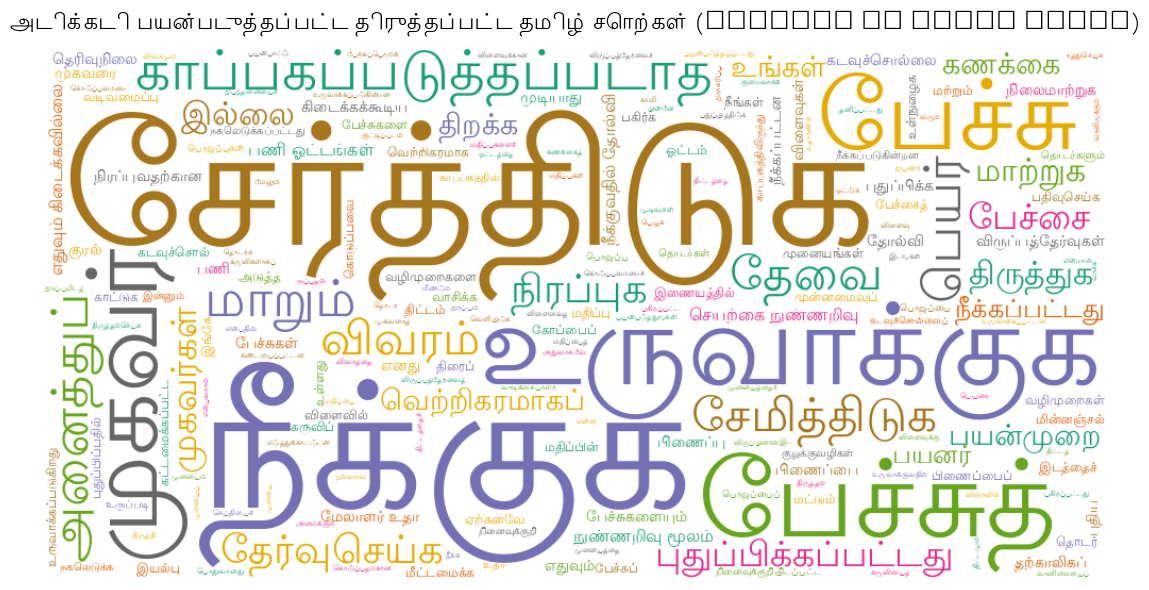

In [22]:
import os
import shutil
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from wordcloud import WordCloud

# 1. Install the official lohit-taml font package via apt
print("Installing official lohit-taml system font package...")
os.system('apt-get update > /dev/null 2>&1')
os.system('apt-get install -y fonts-lohit-taml > /dev/null 2>&1')

# 2. Reset the matplotlib font cache completely
cache_dir = mpl.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# 3. Locate the installed system Lohit Tamil font path
tamil_font_path = '/usr/share/fonts/truetype/lohit-tamil/Lohit-Tamil.ttf'

if os.path.exists(tamil_font_path):
    try:
        fm.fontManager.addfont(tamil_font_path)
        prop = fm.FontProperties(fname=tamil_font_path)
        plt.rcParams['font.family'] = prop.get_name()
        print(f"Successfully loaded and registered system font: {tamil_font_path}")
    except Exception as e:
        print(f"Failed to register font: {e}")
        tamil_font_path = None
else:
    print("Error: System Tamil font could not be located.")
    tamil_font_path = None

# Extract human-refined (HT) terms from our glossary
refined_words = list(term_rules.values())
text_data = " ".join(refined_words)

# 4. Generate Word Cloud
if tamil_font_path:
    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color='white',
        font_path=tamil_font_path,
        colormap='Dark2',
        regexp=r"[\u0b80-\u0bff]+"  # Capture Tamil unicode blocks exclusively
    ).generate(text_data)
else:
    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color='white',
        colormap='Dark2'
    ).generate(text_data)

# Display the word cloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

# Apply the custom Tamil font properties to the title
if tamil_font_path:
    plt.title('அடிக்கடி பயன்படுத்தப்பட்ட திருத்தப்பட்ட தமிழ் சொற்கள் (Refined HT Words Cloud)', fontproperties=prop, fontsize=16, pad=15, weight='bold')
else:
    plt.title('Refined HT Words Cloud', fontsize=16, pad=15, weight='bold')

plt.tight_layout()
plt.show()

In [25]:
import pandas as pd

# Convert the glossary rules dictionary to a list of rows
glossary_data = [
    {"Machine Translation (MT)": mt, "Human Refinement (HT)": ht}
    for mt, ht in term_rules.items()
]

# Create DataFrame
df_glossary = pd.DataFrame(glossary_data)

# Save to CSV in /content/
csv_path = "/content/ui_glossary_rules.csv"
df_glossary.to_csv(csv_path, index=False, encoding="utf-8-sig")

print(f"Successfully saved {len(df_glossary)} glossary rules to '{csv_path}'.")

# Display the first 10 rows as a preview
display(df_glossary.head(10))

Successfully saved 242 glossary rules to '/content/ui_glossary_rules.csv'.


,Machine Translation (MT),Human Refinement (HT)
0,ரத்து செய்,ரத்துசெய்க
1,புதுப்பி,புதுப்பித்திடுக
2,தொடரவும்,தொடர்க
3,நீக்கு,நீக்குக
4,சேமி,சேமித்திடுக
5,பின்னால்,பின்னே
6,உருக்கு,உருவாக்குக
7,குறைவாகக் காட்டு,குறைவாகக் காட்டுக
8,மேலும் காட்டு,மேலும் காட்டுக
9,திருத்து,திருத்துக


In [26]:
import pandas as pd
from IPython.display import display, HTML

# Filter parallel corpus specifically for the 'Workflow' category
workflow_df = df[df['category'] == 'Workflow'].copy()

# Select segments where human refinement (HT) modified the machine translation (MT)
workflow_modified = workflow_df[workflow_df['is_modified']].head(8)

# Format a beautiful comparison dataframe
analysis_records = []
for _, row in workflow_modified.iterrows():
    analysis_records.append({
        "Key Path (ID)": row['key_path'],
        "English Source": row['en_source'],
        "Machine Translation (MT)": row['tamil_mt'],
        "Human Refinement (HT)": row['tamil_ht']
    })

df_analysis = pd.DataFrame(analysis_records)

# Custom CSS to render crisp Tamil text and highlighted columns
html_style_wf = """
<style>
    .wf-table {
        font-family: 'Arial', sans-serif;
        border-collapse: collapse;
        width: 100%;
        margin: 20px 0;
    }
    .wf-table td, .wf-table th {
        border: 1px solid #ddd;
        padding: 10px 12px;
    }
    .wf-table tr:nth-child(even){background-color: #fcfcfc;}
    .wf-table tr:hover {background-color: #f1f1f1;}
    .wf-table th {
        padding-top: 12px;
        padding-bottom: 12px;
        text-align: left;
        background-color: #2b5c8f;
        color: white;
        font-weight: bold;
    }
    .wf-title {
        color: #2b5c8f;
        font-family: 'Arial', sans-serif;
        font-size: 18px;
        font-weight: bold;
        margin-bottom: 5px;
    }
</style>
"""

html_table_wf = df_analysis.to_html(classes='wf-table', index=False)
display(HTML(html_style_wf + "<div class='wf-title'>Linguistic Comparison: Workflow Category (MT vs HT)</div>" + html_table_wf))

Key Path (ID),English Source,Machine Translation (MT),Human Refinement (HT)
Workflow.title,Workflow,பணிப்பாய்வு,பணி ஓட்டம்
Workflow.whatIsWorkflow,What is a Workflow?,பணிப்பாய்வு என்றால் என்ன?,பணி ஓட்டம் என்றால் என்ன?
Workflow.myWorkflows,My Workflows,எனது பணிப்பாய்வுகள்,எனது பணி ஓட்டங்கள்
Workflow.sharedWorkflows,Shared Workflows,பகிரப்பட்ட பணிப்பாய்வுகள்,பகிரப்பட்ட பணி ஓட்டங்கள்
Workflow.availableWorkflows,Available Workflows,கிடைக்கும் பணிப்பாய்வுகள்,கிடைக்கக்கூடிய பணி ஓட்டங்கள்
Workflow.noAvailableWorkflows,No workflows available,பணிப்பாய்வுகள் எதுவும் இல்லை,பணி ஓட்டங்கள் எதுவும் கிடைக்கவில்லை
Workflow.noAvailableWorkflowsDescription,Ask your admin to share workflows with you,உங்களுடன் பணிப்பாய்வுகளைப் பகிர உங்கள் நிர்வாகியிடம் கேட்கவும்,பணி ஓட்டங்களை உங்களுடன் பகிருமாறு உங்கள் நிர்வாகியிடம் கேட்கவும்
Workflow.createWorkflow,Create Workflow,பணிப்பாய்வை உருவாக்கு,பணி ஓட்டத்தை உருவாக்குக


In [27]:
import pandas as pd
import re
from IPython.display import display, HTML

# Define the target words we want to analyze
target_terms = ['Chatbot', 'Custom', 'Network']

# Create lists to hold matching records
matched_records = []

# Search case-insensitively in the English source text
for term in target_terms:
    pattern = re.compile(rf'\b{term}\b', re.IGNORECASE)
    term_df = df[df['en_source'].str.contains(pattern, na=False)].copy()
    term_df['matched_term'] = term
    matched_records.append(term_df)

# Combine matches into a single DataFrame
focus_df = pd.concat(matched_records, ignore_index=True)

# 1. Calculate and display modification statistics for each term
stats_list = []
for term in target_terms:
    sub_df = focus_df[focus_df['matched_term'] == term]
    total = len(sub_df)
    modified = sub_df['is_modified'].sum()
    mod_ratio = (modified / total) * 100 if total > 0 else 0
    stats_list.append({
        "Term": term,
        "Total Occurrences": total,
        "Modified (HT != MT)": modified,
        "Unmodified (HT = MT)": total - modified,
        "Modification %": f"{mod_ratio:.1f}%"
    })

df_term_stats = pd.DataFrame(stats_list)

# Render Summary Stats HTML Table
html_stats_style = """
<style>
    .term-stats-table {
        font-family: 'Arial', sans-serif;
        border-collapse: collapse;
        width: 100%;
        margin-bottom: 20px;
    }
    .term-stats-table td, .term-stats-table th {
        border: 1px solid #ddd;
        padding: 10px 12px;
    }
    .term-stats-table tr:nth-child(even){background-color: #fcfcfc;}
    .term-stats-table th {
        background-color: #e65100;
        color: white;
        font-weight: bold;
    }
</style>
"""
display(HTML(html_stats_style + "<h3>Summary Metrics for Selected Terms</h3>" + df_term_stats.to_html(classes='term-stats-table', index=False)))

# 2. Extract and display representative examples for each term
examples = []
for term in target_terms:
    examples.append(focus_df[(focus_df['matched_term'] == term) & (focus_df['is_modified'])].head(3))

df_examples = pd.concat(examples, ignore_index=True)[['matched_term', 'key_path', 'en_source', 'tamil_mt', 'tamil_ht']]

# Render Detailed Examples HTML Table
html_examples_style = """
<style>
    .term-ex-table {
        font-family: 'Arial', sans-serif;
        border-collapse: collapse;
        width: 100%;
        margin-top: 10px;
    }
    .term-ex-table td, .term-ex-table th {
        border: 1px solid #ddd;
        padding: 10px 12px;
    }
    .term-ex-table tr:nth-child(even){background-color: #fff3e0;}
    .term-ex-table th {
        background-color: #ef6c00;
        color: white;
        font-weight: bold;
    }
</style>
"""
display(HTML(html_examples_style + "<h3>Detailed Comparison of Key UI Refinements</h3>" + df_examples.to_html(classes='term-ex-table', index=False)))

Term,Total Occurrences,Modified (HT != MT),Unmodified (HT = MT),Modification %
Chatbot,15,15,0,100.0%
Custom,3,3,0,100.0%
Network,0,0,0,0.0%


matched_term,key_path,en_source,tamil_mt,tamil_ht
Chatbot,Workflow.createWorkflowDescription,Create workflows as powerful tools for your chatbot.,உங்கள் அரட்டைப் படத்திற்கான சக்திவாய்ந்த கருவிகளாக பணிப்பாய்வுகளை உருவாக்குங்கள்.,உங்கள் பேச்சுப்பொறிக்குச் சக்திவாய்ந்த கருவிகளாகப் பணி ஓட்டங்களை உருவாக்குங்கள்.
Chatbot,Workflow.workflowNamePlaceholder,Chatbot will recognize this as tool name,இதைக் கருவிப் பெயராக அரட்டைப் படு തിരിച്ചறியும்,பேச்சுப்பொறி இதைத்தான் கருவியின் பெயராக அடையாளம் காணும்
Chatbot,Workflow.descriptionPlaceholder,Chatbot will see this as tool description,இதைக் கருவி விளக்கமாக அரட்டைப் படு பார்க்கும்,பேச்சுப்பொறி இதைத்தான் கருவியின் விவரமாகக் காணும்
Custom,Workflow.kindsDescription.code,"Execute custom code scripts with access to previous node data.\n\nRun JavaScript, Python, or other languages within your workflow (coming soon).","முந்தைய முனை தரவுக்கான அணுகலுடன் தனிப்பயன் குறியீட்டு ஸ்கிரிப்ட்களை இயக்கவும்.\n\nஉங்கள் பணிப்பாய்வுக்குள் JavaScript, Python அல்லது பிற மொழிகளை இயக்கவும் (விரைவில் வருகிறது).","முந்தைய முனையத் தகவல்களுக்கான அணுகலுடன் விருப்பப்படி அமைத்த நிரல்களை இயக்கவும்.\n\nஉங்கள் பணி ஓட்டத்திற்குள் JavaScript, Python அல்லது பிற மொழிகளை இயக்கலாம் (விரைவில் வரும்)."
Custom,Workflow.noTools,No published workflows available.\nCreate workflows to build custom tools.,வெளியிடப்பட்ட பணிப்பாய்வுகள் எதுவும் இல்லை.\nதனிப்பயன் கருவிகளை உருவாக்க பணிப்பாய்வுகளை உருவாக்குங்கள்.,வெளியிடப்பட்ட பணி ஓட்டங்கள் எதுவும் கிடைக்கவில்லை.\nவிருப்பப்படி அமைத்த கருவிகளை உருவாக்க பணி ஓட்டங்களை உருவாக்கவும்.
Custom,Layout.customInstructions,Custom Instructions,தனிப்பயன் வழிமுறைகள்,விருப்பப்படி அமைத்த வழிமுறைகள்


In [28]:
import pandas as pd
from IPython.display import display, HTML

# Calculate modification statistics grouped by category
cat_stats = df.groupby('category').agg(
    Total_Segments=('is_modified', 'count'),
    Refined_Segments=('is_modified', 'sum')
).reset_index()

# Calculate Unmodified and Refinement %
cat_stats['Unmodified'] = cat_stats['Total_Segments'] - cat_stats['Refined_Segments']
cat_stats['Refinement %'] = (cat_stats['Refined_Segments'] / cat_stats['Total_Segments']) * 100

# Sort by percentage of refinement required (descending)
cat_stats_sorted = cat_stats.sort_values(by='Refinement %', ascending=False)

# Format Refinement % as string
cat_stats_sorted['Refinement %'] = cat_stats_sorted['Refinement %'].map('{:.1f}%'.format)

# Style HTML table
html_style_summary = """
<style>
    .summary-table {
        font-family: 'Arial', sans-serif;
        border-collapse: collapse;
        width: 100%;
        margin-top: 15px;
    }
    .summary-table td, .summary-table th {
        border: 1px solid #ddd;
        padding: 10px 12px;
    }
    .summary-table tr:nth-child(even){background-color: #f9f9f9;}
    .summary-table th {
        background-color: #3f51b5;
        color: white;
        font-weight: bold;
    }
</style>
"""

display(HTML(html_style_summary + "<h3>UI Categories Ranked by Human Refinement Rate</h3>" + cat_stats_sorted.to_html(classes='summary-table', index=False)))

category,Total_Segments,Refined_Segments,Unmodified,Refinement %
KeyboardShortcuts,10,10,0,100.0%
Info,2,2,0,100.0%
Workflow,99,93,6,93.9%
Agent,49,42,7,85.7%
Auth,27,23,4,85.2%
Common,43,34,9,79.1%
Chat,133,97,36,72.9%
Layout,55,39,16,70.9%
User,85,48,37,56.5%
Archive,22,11,11,50.0%
